In [1]:
!pip install -q -U transformers accelerate

import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
import re
import json
import glob
import time
import subprocess
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image
from transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
device: cuda


In [2]:
MODEL_NAME = "Qwen/Qwen2.5-VL-7B-Instruct"

processor = AutoProcessor.from_pretrained(
    MODEL_NAME,
    min_pixels=256 * 28 * 28,
    max_pixels=1024 * 28 * 28,
)
model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16,
    device_map="auto",
    max_memory={0: "12GiB", 1: "12GiB"},
    attn_implementation="sdpa",
)
DT = torch.float16
model.eval()
for p_ in model.parameters():
    p_.requires_grad_(False)

lm = model.model.language_model
lm_head = model.lm_head
layers = lm.layers
n_layer = model.config.text_config.num_hidden_layers
n_head = model.config.text_config.num_attention_heads
hidden_dim = model.config.text_config.hidden_size
head_dim = layers[0].self_attn.o_proj.in_features // n_head
IMAGE_TOKEN_ID = model.config.image_token_id
assert len(layers) == n_layer
print(n_layer, "language model layers,", n_head, "heads,", head_dim, "head dim, image token id", IMAGE_TOKEN_ID, "| attention", model.config.text_config._attn_implementation)

preprocessor_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.37k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/5.70k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/216 [00:00<?, ?B/s]

28 language model layers, 28 heads, 128 head dim, image token id 151655 | attention sdpa


In [3]:
INPUT = "/kaggle/input/datasets/nocturnalnerd18"
USERNAME = "nocturnalnerd18"
AMBER_IMAGE_DIR = "/kaggle/input/datasets/nocturnalnerd18/amber-hallucination/image"

N_UNITS = 100
DRIVEN_TE = -1.0
SLUG = f"{USERNAME}/patch-qwen-circuit"
POS_STEPS = [8, 16, 32, 64, 128]
NEG_STEPS = [8, 32]
SIGNED_STEPS = [16, 64]
TARGET = 0.8
MAX_HOURS = 9.0
PILOT_UNITS = 2
BATCH_SAVE_SIZE = 20
UPLOAD_EVERY = 2
CHECK_TOL = 0.25
TAIL_N = 5
GROUPS = ["visual", "text", "tail"]
OUT_DIR = "/kaggle/working/patch_qwen_circuit"
os.makedirs(OUT_DIR, exist_ok=True)

FIXED_CORE = [
    ("head", 15, 26, "all"), ("head", 20, 2, "all"), ("mlp", 1, -1, "visual"), ("mlp", 14, -1, "all"), ("mlp", 15, -1, "all"),
    ("mlp", 17, -1, "all"), ("mlp", 18, -1, "all"), ("mlp", 19, -1, "all"), ("mlp", 20, -1, "all"), ("mlp", 21, -1, "all"),
]


def load_image(path):
    return Image.open(path).convert("RGB")


def build_inputs(image, text):
    conversation = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": text}]}]
    prompt_text = processor.apply_chat_template(conversation, add_generation_prompt=True)
    return processor(text=prompt_text, images=image, return_tensors="pt").to(model.device, DT)


def resolve_image_path(q):
    if q["question_id"].startswith("amber_"):
        return os.path.join(AMBER_IMAGE_DIR, f"{q['image_id']}.jpg")
    return None


def batch_number(path):
    return int(re.search(r"_batch_(\d+)\.pt$", path).group(1))


with open(f"{INPUT}/vlm-questions/all_questions.json") as f:
    all_questions = json.load(f)
assert len(all_questions) == 17492, "attach vlm-questions version 2"
question_by_id = {q["question_id"]: q for q in all_questions}
with open(f"{INPUT}/dla-qwen/dla_meta.json") as f:
    dla_meta = json.load(f)
PAIRS = {k: tuple(v) for k, v in dla_meta["pairs"].items()}
for prefix, (yes_id, no_id) in PAIRS.items():
    words = [processor.tokenizer.decode([i]).strip() for i in (yes_id, no_id)]
    print(prefix, yes_id, no_id, words)
    assert [w.lower() for w in words] == ["yes", "no"], words
assert "amber_" in PAIRS

atp = {}
atp_files = sorted(glob.glob(f"{INPUT}/atp-qwen-noising/**/*_batch_*.pt", recursive=True), key=lambda p: (os.path.basename(p).split("_batch_")[0], batch_number(p)))
for path in atp_files:
    for e in torch.load(path):
        if e["ok"]:
            atp[e["question_id"]] = {k: e[k] for k in (
                "question_id", "image_id", "hallucination_type", "stratum", "group", "source", "split", "sign", "seed",
                "delta_clean", "delta_corrupt", "TE", "noise_used", "head", "mlp",
            )}
print(f"atp-qwen-noising: {len(atp_files)} batch files, {len(atp)} ok entries")
assert len(atp) >= 0.98 * 2927, "attach atp-qwen-noising (all batches)"

meta = pd.DataFrame([{k: v for k, v in a.items() if k not in ("head", "mlp")} for a in atp.values()])
meta["gap_clean"] = meta.sign * meta.delta_clean


def image_ok(qid):
    path = resolve_image_path(question_by_id[qid])
    return path is not None and os.path.exists(path)

fy_all = meta[(meta.stratum == "false_yes") & (meta.hallucination_type == "attribute") & (meta.TE < DRIVEN_TE)]
ty_all = meta[(meta.stratum == "true_yes") & (meta.hallucination_type == "attribute")]
rng = np.random.default_rng(0)
units = []
for (s, sp), g in fy_all.groupby(["source", "split"]):
    pool = ty_all[(ty_all.source == s) & (ty_all.split == sp)].set_index("question_id").gap_clean
    ids = g.question_id.tolist()
    gaps = g.set_index("question_id").gap_clean
    for rank, i in enumerate(rng.permutation(len(ids))):
        qid = ids[i]
        ctrl = None
        if len(pool):
            ctrl = (pool - gaps[qid]).abs().idxmin()
            pool = pool.drop(ctrl)
        units.append({"fy": qid, "ctrl": ctrl, "key": (rank + 0.5) / len(ids), "stratum": f"{s}/{sp}"})
units.sort(key=lambda u: (u["key"], u["stratum"]))
units = [u for u in units if image_ok(u["fy"]) and (u["ctrl"] is None or image_ok(u["ctrl"]))]
for i, u in enumerate(units):
    u["uid"] = i
print(len(units), "driven attribute false_yes units,", sum(u["ctrl"] is not None for u in units), "with a matched true_yes control")
stage_units = units[:N_UNITS]
uid_of = {}
for u in stage_units:
    uid_of[u["fy"]] = u["uid"]
    if u["ctrl"] is not None:
        uid_of[u["ctrl"]] = u["uid"]
stage_ids = list(uid_of)
print(f"{len(stage_units)} units, {len(stage_ids)} questions")
print(pd.Series([u["stratum"] for u in stage_units]).value_counts().to_string())


def comp_name(kind, layer, head, group):
    base = f"L{layer} H{head}" if kind == "head" else f"L{layer} MLP"
    return f"{base} {group}"


CORE = {}
for c in FIXED_CORE:
    CORE[comp_name(*c)] = c
survivors_path = f"{INPUT}/patch-qwen-effects/survivors.json"
if os.path.exists(survivors_path):
    with open(survivors_path) as f:
        survivors = json.load(f)
    for s_ in survivors.values():
        c = s_["cell"]
        cell = (c["kind"], c["layer"], c["head"], c["group"])
        if comp_name(*cell) not in CORE and comp_name(c["kind"], c["layer"], c["head"], "all") not in CORE:
            CORE[comp_name(*cell)] = cell
    print(len(survivors), "survivors read from patch-qwen-effects")
else:
    print("patch-qwen-effects not attached, using the fixed core only")
CORE_COMPS = list(CORE.values())
print(len(CORE_COMPS), "core circuit components:", list(CORE))

train_fy = [q for q in fy_all[fy_all.split == "train"].question_id if q in atp]
sup_head = np.zeros((len(GROUPS), n_layer, n_head))
sup_mlp = np.zeros((len(GROUPS), n_layer))
for q in train_fy:
    a = atp[q]
    sup_head += (-a["sign"] * a["head"]).numpy()
    sup_mlp += (-a["sign"] * a["mlp"]).numpy()
sup_head /= len(train_fy)
sup_mlp /= len(train_fy)
print(f"signed attribution patching support for Yes on {len(train_fy)} driven train false_yes questions")


def comp_support(c):
    kind, layer, head, group = c
    arr = sup_head[:, layer, head] if kind == "head" else sup_mlp[:, layer]
    return float(arr.sum() if group == "all" else arr[GROUPS.index(group)])


PROMOTERS = [c for c in CORE_COMPS if comp_support(c) > 0]
BRAKES = [c for c in CORE_COMPS if comp_support(c) <= 0]
print("core promoters (positive support):", [(comp_name(*c), round(comp_support(c), 3)) for c in PROMOTERS])
print("core brakes (non-positive support):", [(comp_name(*c), round(comp_support(c), 3)) for c in BRAKES])
core_all = {(k, l, h) for k, l, h, g in CORE_COMPS if g == "all"}
cands = [("head", l, h, "all") for l in range(n_layer) for h in range(n_head)] + [("mlp", l, -1, "all") for l in range(n_layer)]
cands = [c for c in cands if (c[0], c[1], c[2]) not in core_all]
RANKED_POS = [c for c in sorted(cands, key=lambda c: -comp_support(c)) if comp_support(c) > 0]
RANKED_NEG = [c for c in sorted(cands, key=lambda c: comp_support(c)) if comp_support(c) < 0]
print(len(RANKED_POS), "positive and", len(RANKED_NEG), "negative candidate additions")
print("top positive:", [(comp_name(*c), round(comp_support(c), 3)) for c in RANKED_POS[:8]])
print("top negative:", [(comp_name(*c), round(comp_support(c), 3)) for c in RANKED_NEG[:8]])


def prep(qid):
    q = question_by_id[qid]
    inputs = build_inputs(load_image(resolve_image_path(q)), q["question_text"])
    ids = inputs["input_ids"]
    T = ids.shape[1]
    vis = ids[0] == IMAGE_TOKEN_ID
    tail = torch.zeros(T, dtype=torch.bool, device=ids.device)
    tail[-TAIL_N:] = True
    text = ~vis & ~tail
    assert int(vis.sum()) == int(inputs["image_grid_thw"].prod()) // 4 and not bool((vis & tail).any())
    yes_id, no_id = PAIRS[qid.split("_")[0] + "_"]
    return {
        "qid": qid, "T": T, "inputs": inputs, "vis": vis, "yes_id": yes_id, "no_id": no_id,
        "idx": {
            "all": torch.arange(T), "visual": torch.nonzero(vis.cpu())[:, 0],
            "text": torch.nonzero(text.cpu())[:, 0], "tail": torch.nonzero(tail.cpu())[:, 0],
        },
        "sign": 1.0 if q["ground_truth_answer"].strip().lower() == "yes" else -1.0,
    }

amber_ 9454 2753 ['Yes', 'No']
reefknot_ 9693 2152 ['yes', 'no']
atp-qwen-noising: 15 batch files, 2927 ok entries
93 driven attribute false_yes units, 93 with a matched true_yes control
93 units, 186 questions
amber/train    73
amber/test     10
amber/val      10
11 survivors read from patch-qwen-effects
10 core circuit components: ['L15 H26 all', 'L20 H2 all', 'L1 MLP visual', 'L14 MLP all', 'L15 MLP all', 'L17 MLP all', 'L18 MLP all', 'L19 MLP all', 'L20 MLP all', 'L21 MLP all']
signed attribution patching support for Yes on 73 driven train false_yes questions
core promoters (positive support): [('L15 H26 all', 0.546), ('L17 MLP all', 0.68), ('L18 MLP all', 1.711), ('L19 MLP all', 1.969), ('L20 MLP all', 1.476), ('L21 MLP all', 0.575)]
core brakes (non-positive support): [('L20 H2 all', -0.754), ('L1 MLP visual', -2.678), ('L14 MLP all', -0.033), ('L15 MLP all', -0.939)]
445 positive and 358 negative candidate additions
top positive: [('L18 H4 all', 2.25), ('L22 MLP all', 2.126), ('

In [4]:
STATE = {"noise": None, "seed": 0, "capture": False, "live": None, "vis": None, "freeze": None}


def _layer_pre(l):
    def hook(module, args, kwargs):
        if l != 0 or STATE["noise"] is None:
            return None
        h = args[0] if args else kwargs["hidden_states"]
        vis = STATE["vis"]
        h = h.clone()
        x = h[:, vis].float()
        generator = torch.Generator().manual_seed(STATE["seed"])
        noise = torch.randn(x.shape, generator=generator).to(h.device)
        h[:, vis] = (x + noise * x.std() * STATE["noise"]).to(h.dtype)
        if args:
            return (h,) + tuple(args[1:]), kwargs
        kwargs = dict(kwargs)
        kwargs["hidden_states"] = h
        return args, kwargs
    return hook


def _z_pre(l):
    def hook(module, args):
        z = args[0]
        fz = STATE["freeze"]
        if fz is not None:
            m = fz["z"][l]
            if m is None:
                return None
            B, T = z.shape[0], z.shape[1]
            src = fz["src"]["z"][l][0].view(T, n_head, head_dim).to(z.device, z.dtype)
            z4 = torch.where(m.to(z.device)[None, :, :, None], src[None], z.view(B, T, n_head, head_dim))
            return (z4.view(B, T, n_head * head_dim),) + tuple(args[1:])
        if STATE["capture"]:
            STATE["live"]["z"][l] = z
        return None
    return hook


def _mlp_fwd(l):
    def hook(module, args, output):
        fz = STATE["freeze"]
        if fz is not None:
            m = fz["m"][l]
            if m is None:
                return None
            src = fz["src"]["mlp"][l][0].to(output.device, output.dtype)
            return torch.where(m.to(output.device)[None, :, None], src[None], output)
        if STATE["capture"]:
            STATE["live"]["mlp"][l] = output
        return None
    return hook


_handles = []
for l, layer in enumerate(layers):
    _handles.append(layer.register_forward_pre_hook(_layer_pre(l), with_kwargs=True))
    _handles.append(layer.self_attn.o_proj.register_forward_pre_hook(_z_pre(l)))
    _handles.append(layer.mlp.register_forward_hook(_mlp_fwd(l)))
print(len(_handles), "hooks registered")

84 hooks registered


In [5]:
@torch.no_grad()
def run_forward(p, noise, seed, freeze=None, capture=False):
    STATE.update(noise=noise, seed=seed, capture=capture, freeze=freeze, vis=p["vis"])
    if capture:
        STATE["live"] = {"z": [None] * n_layer, "mlp": [None] * n_layer}
    out = model(**p["inputs"], use_cache=False, logits_to_keep=1)
    logits = out.logits[0, -1].float()
    delta = float(p["sign"] * (logits[p["yes_id"]] - logits[p["no_id"]]))
    result = {"acts": STATE["live"], "delta": delta} if capture else delta
    STATE.update(noise=None, capture=False, freeze=None, live=None)
    del out, logits
    return result


def build_mask(p, comps):
    T = p["T"]
    hm = torch.zeros(n_layer, T, n_head, dtype=torch.bool)
    mm = torch.zeros(n_layer, T, dtype=torch.bool)
    for kind, layer, head, group in comps:
        idx = p["idx"][group]
        if kind == "head":
            hm[layer, idx, head] = True
        else:
            mm[layer, idx] = True
    return hm, mm


def make_freeze(hm, mm, src, invert):
    zs, ms = [], []
    for l in range(n_layer):
        a, b = hm[l], mm[l]
        if invert:
            a, b = ~a, ~b
        zs.append(a if bool(a.any()) else None)
        ms.append(b if bool(b.any()) else None)
    return {"z": zs, "m": ms, "src": src["acts"]}


def three_configs(p, clean, corrupt, comps, seed, noise):
    hm, mm = build_mask(p, comps)
    knock = run_forward(p, None, seed, make_freeze(hm, mm, corrupt, False))
    restore = run_forward(p, noise, seed, make_freeze(hm, mm, clean, False))
    rest = run_forward(p, noise, seed, make_freeze(hm, mm, clean, True))
    return [knock, restore, rest]


STEP_NAMES = ["core", "promoters", "brakes"] + [f"P+pos{k}" for k in POS_STEPS] + [f"B+neg{k}" for k in NEG_STEPS] + [f"signed{k}" for k in SIGNED_STEPS]
CONFIG_NAMES = ["knockout", "restored", "rest_restored"]


def step_components(name):
    if name == "core":
        return list(CORE_COMPS)
    if name == "promoters":
        return list(PROMOTERS)
    if name == "brakes":
        return list(BRAKES)
    if name.startswith("P+pos"):
        return list(PROMOTERS) + RANKED_POS[:int(name[5:])]
    if name.startswith("B+neg"):
        return list(BRAKES) + RANKED_NEG[:int(name[5:])]
    k = int(name[6:])
    return list(CORE_COMPS) + RANKED_POS[:k] + RANKED_NEG[:k]


def circuit_curve(p, clean, corrupt, seed, noise):
    return np.array([three_configs(p, clean, corrupt, step_components(n), seed, noise) for n in STEP_NAMES], dtype=np.float32)


ALL_COMPS = [("head", l, h, "all") for l in range(n_layer) for h in range(n_head)] + [("mlp", l, -1, "all") for l in range(n_layer)]

In [6]:
pilot_ids = [q for u in stage_units for q in (u["fy"], u["ctrl"]) if q is not None and image_ok(q)][:2 * PILOT_UNITS]
secs, base_err, id_err, plain_err = [], [], [], []
for qid in pilot_ids:
    a = atp[qid]
    p = prep(qid)
    t0 = time.time()
    clean = run_forward(p, None, a["seed"], capture=True)
    corrupt = run_forward(p, a["noise_used"], a["seed"], capture=True)
    base_err.append(max(abs(clean["delta"] - a["delta_clean"]), abs(corrupt["delta"] - a["delta_corrupt"])))
    plain_err.append(max(abs(run_forward(p, None, a["seed"]) - clean["delta"]), abs(run_forward(p, a["noise_used"], a["seed"]) - corrupt["delta"])))
    t_cap = time.time() - t0
    all_knock, all_restore, all_rest = three_configs(p, clean, corrupt, ALL_COMPS, a["seed"], a["noise_used"])
    none_knock, none_restore, none_rest = three_configs(p, clean, corrupt, [], a["seed"], a["noise_used"])
    id_err.append(max(abs(all_knock - corrupt["delta"]), abs(all_restore - clean["delta"]), abs(all_rest - corrupt["delta"]),
                      abs(none_knock - clean["delta"]), abs(none_restore - corrupt["delta"]), abs(none_rest - clean["delta"])))
    t1 = time.time()
    curve = circuit_curve(p, clean, corrupt, a["seed"], a["noise_used"])
    secs.append(t_cap + time.time() - t1)
    print(f"{qid} {a['stratum']:9s} T={p['T']}: {secs[-1]:.1f} s for {len(STEP_NAMES)} steps | clean {clean['delta']:+.2f} (atp run {a['delta_clean']:+.2f}) corrupt {corrupt['delta']:+.2f} ({a['delta_corrupt']:+.2f})")
    print(pd.DataFrame(curve, index=STEP_NAMES, columns=CONFIG_NAMES).round(2).to_string())
    del p, clean, corrupt
    torch.cuda.empty_cache()
print(f"clean and corrupt deltas vs the attribution patching run: max abs diff {max(base_err):.3f}")
print(f"capture runs vs plain runs: max abs diff {max(plain_err):.3f}")
print(f"identity checks (freezing every component, or none, must give the other run or the same run): max abs error {max(id_err):.3f}")
print(f"pilot speed: {np.mean(secs):.1f} s per question, projected {np.mean(secs) * len(stage_ids) / 3600:.1f} h for {len(stage_ids)} questions")
assert max(base_err) < CHECK_TOL, "clean or corrupt deltas differ from the attribution patching collection"
assert max(plain_err) < CHECK_TOL, "capture runs differ from plain runs"
assert max(id_err) < CHECK_TOL, "freezing every component does not reproduce the other run"

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


amber_6622 false_yes T=374: 19.6 s for 12 steps | clean -4.06 (atp run -4.06) corrupt -2.66 (-2.66)
           knockout  restored  rest_restored
core          -1.81     -3.77          -4.11
promoters     -2.84     -3.67          -4.08
brakes        -2.70     -2.14          -4.09
P+pos8        -2.53     -4.16          -2.78
P+pos16       -2.64     -4.45          -2.62
P+pos32       -2.61     -4.47          -1.25
P+pos64       -2.41     -4.16           0.47
P+pos128      -2.28     -4.45           3.06
B+neg8        -3.02     -1.69          -4.12
B+neg32        2.67      7.69          -4.14
signed16      -2.48     -4.30          -4.20
signed64      -2.61     -3.97          -1.55


/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


amber_1225 true_yes  T=309: 18.0 s for 12 steps | clean +4.06 (atp run +4.06) corrupt +1.92 (+1.92)
           knockout  restored  rest_restored
core           2.47      3.94           4.11
promoters      1.59      4.69           4.06
brakes         6.62     -0.56           4.09
P+pos8         1.67      4.30           3.42
P+pos16        1.77      4.59           2.73
P+pos32        1.78      4.53           1.59
P+pos64        1.67      4.39           0.11
P+pos128       1.56      4.62          -2.67
B+neg8         8.48     -2.94           4.09
B+neg32        2.45     -4.47           4.02
signed16       1.84      4.17           4.69
signed64       1.78      3.86           2.80


/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


amber_5612 false_yes T=375: 19.5 s for 12 steps | clean -7.92 (atp run -7.92) corrupt -3.67 (-3.67)
           knockout  restored  rest_restored
core          -3.88     -8.19          -7.95
promoters     -3.84     -8.16          -7.92
brakes        -7.75     -4.64          -7.92
P+pos8        -3.59     -8.69          -6.86
P+pos16       -3.67     -9.38          -6.73
P+pos32       -3.66     -8.77          -5.42
P+pos64       -3.44     -8.62          -3.86
P+pos128      -3.11     -8.94          -2.30
B+neg8        -7.41     -3.00          -8.02
B+neg32       -0.19      4.97          -7.97
signed16      -3.70     -8.59          -7.55
signed64      -3.84     -7.95          -8.31


/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


amber_6663 true_yes  T=328: 18.7 s for 12 steps | clean +7.88 (atp run +7.88) corrupt +0.19 (+0.19)
           knockout  restored  rest_restored
core           0.25      8.30           7.88
promoters      0.58      7.81           7.88
brakes         6.91      0.05           7.89
P+pos8         0.23      8.16           7.02
P+pos16        0.25      8.58           6.94
P+pos32        0.20      8.39           5.14
P+pos64       -0.05      8.52           0.83
P+pos128      -0.11      8.62          -0.14
B+neg8         3.06      0.02           7.89
B+neg32        0.80     -3.12           7.97
signed16       0.27      8.41           8.28
signed64       0.16      7.86           6.48
clean and corrupt deltas vs the attribution patching run: max abs diff 0.000
capture runs vs plain runs: max abs diff 0.000
identity checks (freezing every component, or none, must give the other run or the same run): max abs error 0.000
pilot speed: 19.0 s per question, projected 1.0 h for 186 questions


In [7]:
def _run(cmd):
    r = subprocess.run(cmd, capture_output=True, text=True)
    out = (r.stdout + r.stderr).strip()
    cleaned = "\n".join(l for l in out.splitlines() if "upload info" not in l.lower()).lower()
    bad = ("client error", "forbidden", "unauthorized", "traceback", "error:", "failed")
    return r.returncode == 0 and not any(x in cleaned for x in bad), out


ok, out = _run(["kaggle", "datasets", "download", "-d", SLUG, "-p", OUT_DIR, "--unzip"])
if ok:
    print("restored", len(glob.glob(os.path.join(OUT_DIR, "C_batch_*.pt"))), "batch files from", SLUG)
else:
    if not any(s in out.lower() for s in ("404", "403", "not found", "does not exist", "forbidden")):
        raise RuntimeError("download failed for an unrelated reason, refusing to start fresh:\n" + out)
    print("no existing dataset, starting fresh")
dataset_exists = ok

with open(os.path.join(OUT_DIR, "dataset-metadata.json"), "w") as f:
    json.dump({
        "title": SLUG.split("/")[1],
        "id": SLUG,
        "subtitle": "Signed circuit sets for Qwen attribute",
        "description": "Circuit test with signed sets on Qwen2.5-VL-7B-Instruct for driven attribute false_yes questions (TE below -1) and matched true_yes controls from atp-qwen-noising. "
                       "curve has shape [step, config] holding the sign-corrected Yes minus No logit gap at the last position for three mixed runs. "
                       "knockout: clean input, the set takes its corrupt activations. restored: corrupt input, the set takes its clean activations. rest_restored: corrupt input, every component outside the set takes its clean activation. "
                       "Steps are the core circuit, its promoters and brakes (sign of the attribution patching support for Yes), and the promoters or brakes plus the top positive or negative ranked components. Names are in circuit_meta.json.",
        "licenses": [{"name": "CC0-1.0"}],
    }, f)


def upload(msg):
    global dataset_exists
    version_cmd = ["kaggle", "datasets", "version", "-p", OUT_DIR, "-m", msg]
    create_cmd = ["kaggle", "datasets", "create", "-p", OUT_DIR]
    ok_, out_ = _run(version_cmd if dataset_exists else create_cmd)
    if not ok_ and not dataset_exists:
        time.sleep(30)
        ok_, out2 = _run(version_cmd)
        out_ += "\n--- version retry ---\n" + out2
    if ok_:
        dataset_exists = True
        print(f"    [upload ok] {msg}")
    else:
        cleaned = [l for l in out_.splitlines() if l.strip() and "upload info" not in l.lower() and "B/s]" not in l and "it/s]" not in l]
        print(f"    [UPLOAD FAILED, continuing] account {USERNAME}, dataset {SLUG}\n" + "\n".join(cleaned[-8:]))
    return ok_


with open(os.path.join(OUT_DIR, "circuit_meta.json"), "w") as f:
    json.dump({
        "core": [list(c) for c in CORE_COMPS], "core_names": list(CORE), "step_names": STEP_NAMES, "config_names": CONFIG_NAMES,
        "promoters": [comp_name(*c) for c in PROMOTERS], "brakes": [comp_name(*c) for c in BRAKES],
        "pos_steps": POS_STEPS, "neg_steps": NEG_STEPS, "signed_steps": SIGNED_STEPS,
        "ranked_pos": [list(c) for c in RANKED_POS[:max(POS_STEPS + SIGNED_STEPS)]], "ranked_neg": [list(c) for c in RANKED_NEG[:max(NEG_STEPS + SIGNED_STEPS)]],
        "n_units": N_UNITS, "tail_n": TAIL_N, "pairs": {k_: list(v_) for k_, v_ in PAIRS.items()},
    }, f)


def collect():
    paths = sorted(glob.glob(os.path.join(OUT_DIR, "C_batch_*.pt")), key=batch_number)
    done_ids = set()
    for path in paths:
        done_ids.update(e["question_id"] for e in torch.load(path))
    todo = [q for q in stage_ids if q not in done_ids]
    print(f"{len(stage_ids)} questions, {len(done_ids)} already done, {len(todo)} to run")
    batch_entries, batch_index, failed, missing = [], len(paths), 0, 0
    t_start = time.time()
    stopped = False
    for i, qid in enumerate(todo):
        if not image_ok(qid):
            missing += 1
            continue
        a = atp[qid]
        q = question_by_id[qid]
        entry = {
            "question_id": qid, "uid": uid_of[qid], "image_id": q["image_id"], "stratum": a["stratum"], "source": a["source"], "split": a["split"],
            "sign": 1.0 if q["ground_truth_answer"].strip().lower() == "yes" else -1.0, "atp_delta_clean": a["delta_clean"], "atp_delta_corrupt": a["delta_corrupt"],
        }
        try:
            p = prep(qid)
            clean = run_forward(p, None, a["seed"], capture=True)
            corrupt = run_forward(p, a["noise_used"], a["seed"], capture=True)
            curve = circuit_curve(p, clean, corrupt, a["seed"], a["noise_used"])
            entry.update(ok=True, T=p["T"], delta_clean=clean["delta"], delta_corrupt=corrupt["delta"], curve=torch.from_numpy(curve))
            del p, clean, corrupt
        except torch.cuda.OutOfMemoryError:
            STATE.update(capture=False, live=None, noise=None, freeze=None)
            torch.cuda.empty_cache()
            entry.update(ok=False, reason="oom")
            failed += 1
        batch_entries.append(entry)
        if len(batch_entries) >= BATCH_SAVE_SIZE:
            torch.save(batch_entries, os.path.join(OUT_DIR, f"C_batch_{batch_index}.pt"))
            batch_entries, batch_index = [], batch_index + 1
            if batch_index % UPLOAD_EVERY == 0:
                upload(f"{batch_index} batches")
        if i % 10 == 0 and i > 0:
            torch.cuda.empty_cache()
            avg = (time.time() - t_start) / (i + 1)
            print(f"[{i + 1}/{len(todo)}] {qid} ({avg:.1f} s/question avg, ETA {avg * (len(todo) - i - 1) / 3600:.1f} h, failed {failed}, missing images {missing})")
        if time.time() - t_start > MAX_HOURS * 3600:
            stopped = True
            print(f"time budget of {MAX_HOURS} h reached after {i + 1} questions; re-run this notebook to resume")
            break
    if batch_entries:
        torch.save(batch_entries, os.path.join(OUT_DIR, f"C_batch_{batch_index}.pt"))
    upload("paused" if stopped else "done")
    print(f"done, failed {failed}, missing images {missing}, {(time.time() - t_start) / 3600:.2f} h, complete {not stopped}")


collect()

no existing dataset, starting fresh
186 questions, 0 already done, 186 to run


/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


[11/186] amber_6610 (31.6 s/question avg, ETA 1.5 h, failed 0, missing images 0)
[21/186] amber_7414 (29.1 s/question avg, ETA 1.3 h, failed 0, missing images 0)
[31/186] amber_7894 (30.5 s/question avg, ETA 1.3 h, failed 0, missing images 0)
    [upload ok] 2 batches


/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


[41/186] amber_5682 (32.7 s/question avg, ETA 1.3 h, failed 0, missing images 0)
[51/186] amber_3564 (30.2 s/question avg, ETA 1.1 h, failed 0, missing images 0)
[61/186] amber_3370 (29.4 s/question avg, ETA 1.0 h, failed 0, missing images 0)
[71/186] amber_8194 (28.9 s/question avg, ETA 0.9 h, failed 0, missing images 0)
    [upload ok] 4 batches


...

[81/186] amber_4470 (28.6 s/question avg, ETA 0.8 h, failed 0, missing images 0)
[91/186] amber_3282 (28.2 s/question avg, ETA 0.7 h, failed 0, missing images 0)
[101/186] amber_1280 (28.0 s/question avg, ETA 0.7 h, failed 0, missing images 0)
[111/186] amber_2140 (27.6 s/question avg, ETA 0.6 h, failed 0, missing images 0)
    [upload ok] 6 batches


/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


[121/186] amber_5114 (27.6 s/question avg, ETA 0.5 h, failed 0, missing images 0)
[131/186] amber_5476 (28.0 s/question avg, ETA 0.4 h, failed 0, missing images 0)
[141/186] amber_4808 (27.9 s/question avg, ETA 0.3 h, failed 0, missing images 0)
[151/186] amber_4486 (27.8 s/question avg, ETA 0.3 h, failed 0, missing images 0)
    [upload ok] 8 batches


/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


[161/186] amber_1502 (27.6 s/question avg, ETA 0.2 h, failed 0, missing images 0)
[171/186] amber_3560 (27.6 s/question avg, ETA 0.1 h, failed 0, missing images 0)
[181/186] amber_1518 (27.4 s/question avg, ETA 0.0 h, failed 0, missing images 0)
    [upload ok] done
done, failed 0, missing images 0, 1.41 h, complete True


186 entries, 186 ok, 0 stage questions not done
0 questions with a non-finite value in some step are excluded
--- driven false_yes: share of the clean to corrupt change, ratio of sums over questions, 95% interval over questions ---
           components              knockout              restored                  rest
core               10  +0.95 [+0.93, +0.97]  +0.93 [+0.91, +0.95]  +1.01 [+1.01, +1.01]
promoters           6  +0.91 [+0.89, +0.92]  +0.88 [+0.85, +0.90]  +1.00 [+1.00, +1.00]
brakes              4  +0.39 [+0.32, +0.47]  +0.16 [+0.08, +0.24]  +1.00 [+1.00, +1.00]
P+pos8             14  +0.98 [+0.95, +1.00]  +0.98 [+0.97, +1.00]  +0.85 [+0.83, +0.87]
P+pos16            22  +0.98 [+0.97, +0.99]  +1.02 [+1.00, +1.05]  +0.77 [+0.74, +0.80]
P+pos32            38  +1.00 [+0.99, +1.01]  +1.02 [+1.00, +1.04]  +0.42 [+0.35, +0.48]
P+pos64            70  +1.03 [+1.02, +1.04]  +1.02 [+1.00, +1.04]  +0.09 [-0.01, +0.19]
P+pos128          134  +1.03 [+1.02, +1.04]  +1.07 [+1.06, +1.09

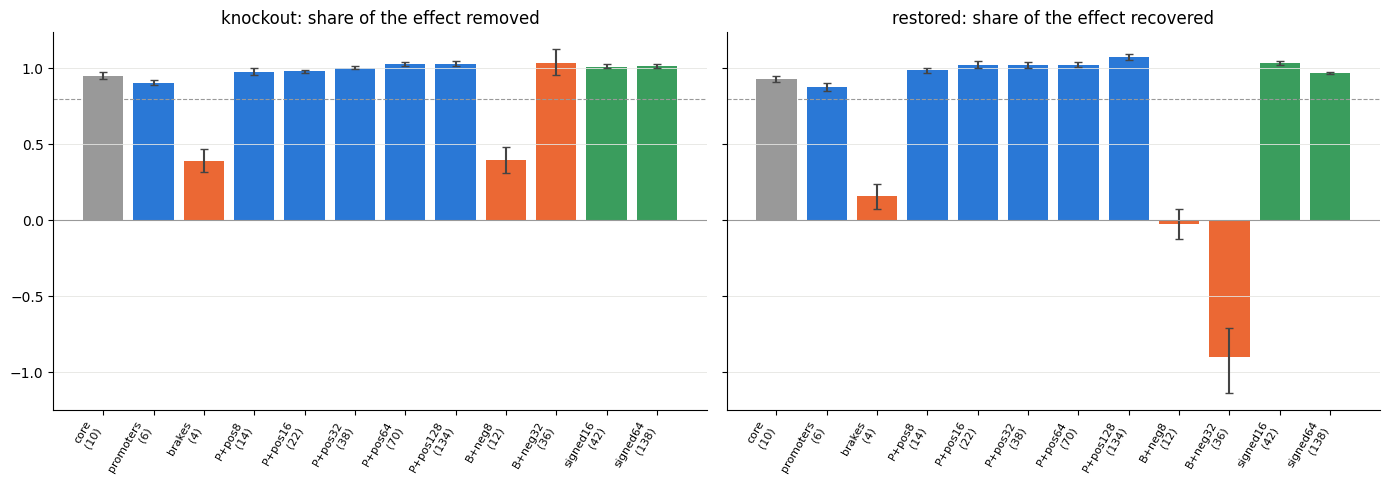

    [upload ok] summary


In [8]:
entries = []
for path in sorted(glob.glob(os.path.join(OUT_DIR, "C_batch_*.pt")), key=batch_number):
    entries.extend(torch.load(path))
good = [e for e in entries if e["ok"]]
assert len({e["question_id"] for e in good}) == len(good), "duplicated entries"
print(f"{len(entries)} entries, {len(good)} ok, {len(stage_ids) - len(good)} stage questions not done")
finite = [bool(np.isfinite(e["curve"].numpy()).all()) for e in good]
print(f"{len(good) - sum(finite)} questions with a non-finite value in some step are excluded")
good = [e for e, ok_ in zip(good, finite) if ok_]

CV = np.stack([e["curve"].numpy() for e in good]).astype(np.float64)
dc = np.array([e["delta_clean"] for e in good])
dk = np.array([e["delta_corrupt"] for e in good])
sign = np.array([e["sign"] for e in good])
role = np.array([e["stratum"] for e in good])
split = np.array([e["split"] for e in good])
uid = np.array([e["uid"] for e in good])
fy = np.flatnonzero(role == "false_yes")
ct = np.flatnonzero(role == "true_yes")
S = len(STEP_NAMES)
n_comp = [len(step_components(n)) for n in STEP_NAMES]
boot_rng = np.random.default_rng(1)
si = {n: i for i, n in enumerate(STEP_NAMES)}


def share_sums(ix):
    den = (dk[ix] - dc[ix]).sum()
    knock = (CV[ix, :, 0] - dc[ix, None]).sum(0) / den
    restored = (CV[ix, :, 1] - dk[ix, None]).sum(0) / -den
    rest = (CV[ix, :, 2] - dk[ix, None]).sum(0) / -den
    return np.stack([knock, restored, rest], 1)


def share_ci(ix, nb=1000):
    point = share_sums(ix)
    draws = boot_rng.integers(0, len(ix), size=(nb, len(ix)))
    boots = np.stack([share_sums(ix[d]) for d in draws])
    return point, np.percentile(boots, 2.5, axis=0), np.percentile(boots, 97.5, axis=0)


print("--- driven false_yes: share of the clean to corrupt change, ratio of sums over questions, 95% interval over questions ---")
point, lo, hi = share_ci(fy)
table = pd.DataFrame({"components": n_comp}, index=STEP_NAMES)
for j, nm in enumerate(["knockout", "restored", "rest"]):
    table[nm] = [f"{point[i, j]:+.2f} [{lo[i, j]:+.2f}, {hi[i, j]:+.2f}]" for i in range(S)]
print(table.to_string())
print("knockout = clean input with the set knocked out (negative: knocking it out strengthens the effect, so the set is a brake);")
print("restored = corrupt input with the set restored to clean; rest = corrupt input with everything outside the set restored to clean")

print("--- additivity of the core: promoters plus brakes against the whole core ---")
for j, nm in enumerate(["knockout", "restored"]):
    print(f"{nm:9s} promoters {point[si['promoters'], j]:+.2f} + brakes {point[si['brakes'], j]:+.2f} = {point[si['promoters'], j] + point[si['brakes'], j]:+.2f} | core {point[si['core'], j]:+.2f}")

print("--- by split (point estimates) ---")
for nm, mask_ in [("train+val", np.isin(split, ["train", "val"])), ("test", split == "test")]:
    ix = np.flatnonzero((role == "false_yes") & mask_)
    if len(ix) >= 5:
        pt = share_sums(ix)
        print(f"{nm:10s} n {len(ix):4d} | " + " | ".join(f"{s_} knock {pt[si[s_], 0]:+.2f} restored {pt[si[s_], 1]:+.2f}" for s_ in ["core", "promoters", "brakes"]))
    else:
        print(f"{nm:10s} n {len(ix)}: too few questions")

pairs = sorted(set(uid[fy]) & set(uid[ct]))
fy_ix = {u: i for u, i in zip(uid[fy], fy)}
ct_ix = {u: i for u, i in zip(uid[ct], ct)}
a_ix = np.array([fy_ix[u] for u in pairs])
b_ix = np.array([ct_ix[u] for u in pairs])
boot = boot_rng.integers(0, len(pairs), size=(1000, len(pairs)))
print(f"--- specificity: false_yes minus matched true_yes support for Yes over {len(pairs)} units, mean [95% interval], logits ---")
sup_ko = -sign[:, None] * (CV[:, :, 0] - dc[:, None])
sup_re = sign[:, None] * (CV[:, :, 1] - dk[:, None])
for nm, arr in [("knockout", sup_ko), ("restored", sup_re)]:
    diff = arr[a_ix] - arr[b_ix]
    means = diff[boot].mean(1)
    for sname in ["core", "promoters", "brakes", f"P+pos{POS_STEPS[-1]}", f"signed{SIGNED_STEPS[-1]}"]:
        i = si[sname]
        print(f"{nm:9s} {sname:12s} {diff.mean(0)[i]:+.3f} [{np.percentile(means[:, i], 2.5):+.3f}, {np.percentile(means[:, i], 97.5):+.3f}]")

ok_steps = [(STEP_NAMES[i], n_comp[i]) for i in range(S) if point[i, 0] >= TARGET and point[i, 1] >= TARGET]
print(f"steps with both knockout and restored at least {TARGET}:", ok_steps if ok_steps else "none")
p_i = si["promoters"]
print(f"verdict: the promoters ({n_comp[p_i]} cells) remove {point[p_i, 0]:.2f} of the effect when knocked out and restore {point[p_i, 1]:.2f}; the brakes shift it by {point[si['brakes'], 0]:+.2f}.")

BLUE, ORANGE, GREY, GREEN = "#2a78d6", "#eb6834", "#999999", "#3a9d5d"
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
xs = np.arange(S)
for ax, j, title in [(axes[0], 0, "knockout: share of the effect removed"), (axes[1], 1, "restored: share of the effect recovered")]:
    ax.bar(xs, point[:, j], color=[ORANGE if n == "brakes" or n.startswith("B+") else BLUE if n == "promoters" or n.startswith("P+") else GREEN if n.startswith("signed") else GREY for n in STEP_NAMES])
    ax.errorbar(xs, point[:, j], yerr=[point[:, j] - lo[:, j], hi[:, j] - point[:, j]], fmt="none", ecolor="#444444", capsize=3)
    ax.axhline(TARGET, color=GREY, lw=0.8, ls="--")
    ax.axhline(0, color=GREY, lw=0.8)
    ax.set_xticks(xs)
    ax.set_xticklabels([f"{n}\n({c})" for n, c in zip(STEP_NAMES, n_comp)], rotation=60, ha="right", fontsize=8)
    ax.set_title(title)
    ax.grid(color="#e5e5e2", lw=0.6, axis="y")
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "circuit_signed.png"), dpi=150)
plt.show()

with open(os.path.join(OUT_DIR, "circuit_summary.json"), "w") as f:
    json.dump({
        "n_ok": len(good), "n_false_yes": int(len(fy)), "n_pairs": len(pairs), "step_names": STEP_NAMES, "n_components": n_comp,
        "shares": point.tolist(), "ci_lo": lo.tolist(), "ci_hi": hi.tolist(), "config_order": CONFIG_NAMES,
        "promoters": [comp_name(*c) for c in PROMOTERS], "brakes": [comp_name(*c) for c in BRAKES], "target": TARGET,
    }, f)
if not upload("summary"):
    print(f"final upload failed; the batch files and summary are still in {OUT_DIR}, which is saved as this notebook's output")